# 1. Imports and global settings

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

In [2]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50

tf.get_logger().setLevel("ERROR")

In [3]:
# Reproducibility seed
# Using a fixed seed helps make results more repeatable
SEED = 42

def fix_random_seed(seed=SEED):
    """Fix random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(SEED)

print("Setup complete")


Setup complete



# 2. Data loading



In [4]:
def load_data_pt(path):
    """
    Load one saved .pt split and convert it to Keras-friendly arrays.

    Returns
    -------
    images:
        NumPy array of shape [N, H, W, 3], values in [0, 1].

    labels:
        NumPy array of shape [N, 10].
        These are multi-hot labels used for training.
    """
    data = torch.load(path, map_location="cpu")

    # Convert [N, H, W] uint8 to [N, H, W, 1] float32.
    images = data["images"].numpy().astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)

    # ResNet-50 expects 3-channel inputs, so replicate the grayscale channel.
    images = np.repeat(images, repeats=3, axis=-1)

    # Multi-label targets.
    labels = data["labels"].numpy().astype("float32")

    # Extra metadata, not required for model training.
    center_labels = data["center_labels"].numpy().astype("int64")
    count_labels = data["count_labels"].numpy().astype("int64")

    meta = {
        "center_labels": center_labels,
        "count_labels": count_labels,
        "num_digits": data["num_digits"].numpy().astype("int64"),
        "all_digit_labels": data["all_digit_labels"].numpy().astype("int64"),
        "all_positions": data["all_positions"].numpy().astype("int64"),
        "label_type": data.get("label_type", None),
    }

    return images, labels, meta


In [5]:

# File paths for train, validation, and test.
train_path = os.path.join("./data/train.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

# Load files if they exist.
if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    x_train, y_train, meta_train = load_data_pt(train_path)
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)
    
    print("Data loaded successfully.")
    print("Train:", x_train.shape, y_train.shape)
    print("Val:  ", x_val.shape, y_val.shape)
    print("Test: ", x_test.shape, y_test.shape)
    print("You can now proceed to model training and evaluation.")
else:
    print("Dataset files not found yet.")


Data loaded successfully.
Train: (50000, 64, 64, 3) (50000, 10)
Val:   (10000, 64, 64, 3) (10000, 10)
Test:  (10000, 64, 64, 3) (10000, 10)
You can now proceed to model training and evaluation.



# 3. Visualization


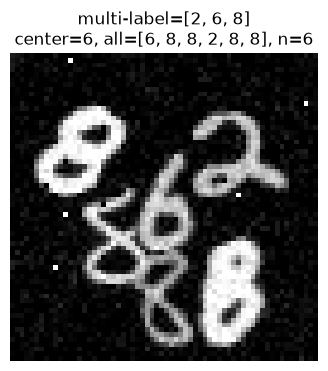

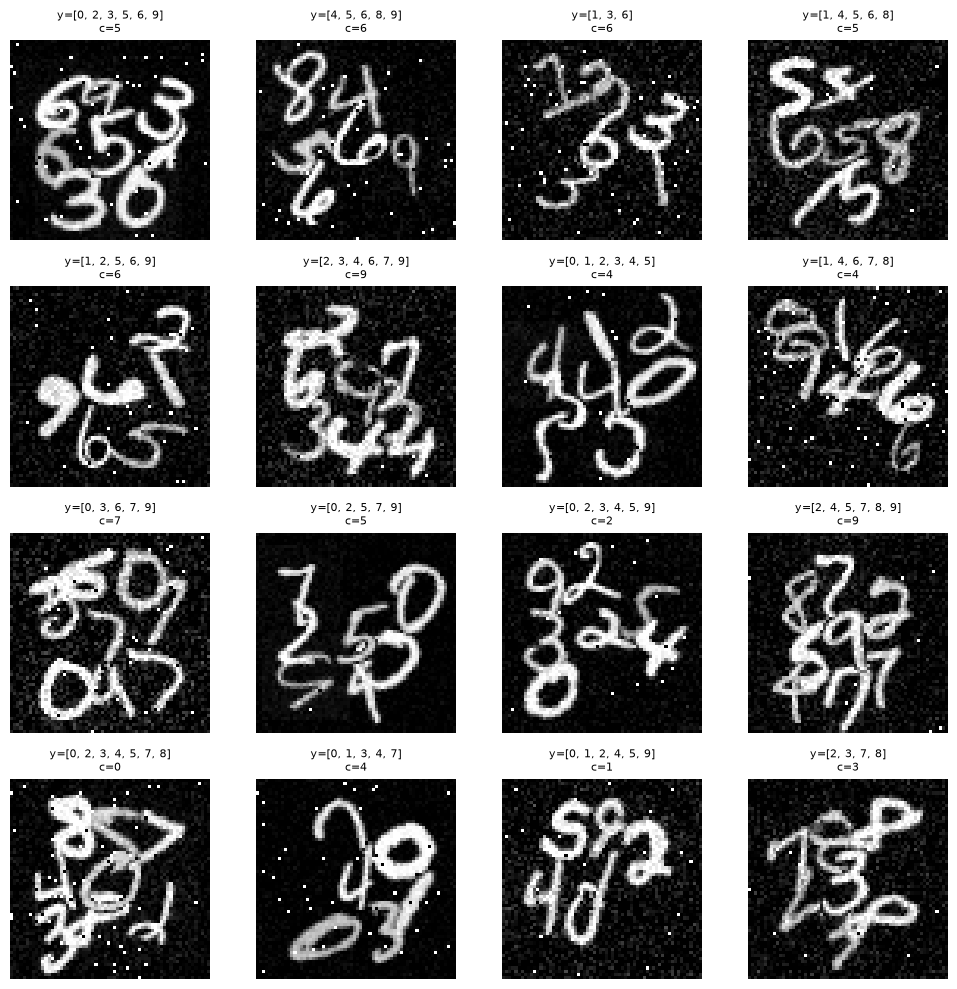

In [6]:
def multihot_to_digits(multihot):
    """
    Convert a multi-hot vector into a list of digit labels.

    Example:
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
        becomes
        [1, 4, 9]
    """
    return np.where(multihot >= 0.5)[0].tolist()


def visualize_one_sample(images, labels, meta, idx=0):
    """Visualize one generated image and its labels."""
    img = images[idx].squeeze()

    digits_present = multihot_to_digits(labels[idx])
    center_label = meta["center_labels"][idx]
    all_labels = meta["all_digit_labels"][idx]
    n_digits = meta["num_digits"][idx]

    # Remove padding values.
    valid_all_labels = all_labels[all_labels >= 0].tolist()

    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap="gray")
    plt.title(
        f"multi-label={digits_present}\n"
        f"center={center_label}, all={valid_all_labels}, n={n_digits}"
    )
    plt.axis("off")
    plt.show()


def visualize_grid(images, labels, meta, num_samples=16):
    """Visualize a grid of random samples."""
    rows = int(np.sqrt(num_samples))
    cols = int(np.ceil(num_samples / rows))

    plt.figure(figsize=(10, 10))

    for i in range(num_samples):
        idx = random.randint(0, len(images) - 1)

        img = images[idx].squeeze()
        digits_present = multihot_to_digits(labels[idx])
        center_label = meta["center_labels"][idx]

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"y={digits_present}\nc={center_label}", fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# Visualize samples if the dataset has been loaded.
if "x_train" in globals():
    visualize_one_sample(x_train, y_train, meta_train, idx=0)
    visualize_grid(x_train, y_train, meta_train, num_samples=16)



# 3. Define exact match accuracy metrics:


In [7]:
def exact_match_accuracy(y_true, y_pred):
    """
    Exact-match accuracy for multi-label classification.

    Steps:
    1. Convert predicted probabilities to binary labels using a threshold.
    2. Compare the whole predicted vector with the true vector.
    3. Count the sample as correct only if every label matches.

    This metric is strict but useful.
    """
    y_pred_binary = tf.cast(y_pred >= 0.5, tf.float32)

    # For each sample, check whether all 10 labels are correct.
    matches = tf.reduce_all(tf.equal(y_true, y_pred_binary), axis=1)

    return tf.reduce_mean(tf.cast(matches, tf.float32))


# 4. Build the ResNet-50 model


In [8]:
def build_resnet50_model(input_shape=(64, 64, 3)):
    """
    Build a randomly initialized ResNet-50 for multi-label classification.

    Important:
    ----------
    The final activation is sigmoid, not softmax.

    Sigmoid allows multiple output classes to be active at the same time.
    """
    inputs = keras.Input(shape=input_shape)

    # Randomly initialized ResNet-50 backbone.
    x = ResNet50(
        include_top=False,
        weights=None,
        input_shape=input_shape,
    )(inputs)

    # Classification head.
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    # Multi-label output.
    # Each output neuron predicts whether one digit class is present.
    outputs = layers.Dense(10, activation="sigmoid")(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="multi_label_resnet50",
    )

    return model


In [9]:
# Build the model
INPUT_SHAPE = (64, 64, 3)

model = build_resnet50_model(input_shape=INPUT_SHAPE)


In [10]:
# Compile the model with appropriate loss and metrics for multi-label classification.

model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.1,
        momentum=0.9,
        use_ema=True,
        # weight_decay=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        exact_match_accuracy,
    ],
)


In [11]:
# Display the model architecture.
model.summary()

Model: "multi_label_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2, 2, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 24,061,706 (91.79 MB)

 Non-trainable params: 53,120 (207.50 KB)


# 5. Train the model


In [12]:
# Training hyperparameters.
BATCH_SIZE = 256
EPOCHS = 100

# Use callbacks to improve training.
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
    ),
]

In [13]:
# Train the model.
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    # callbacks=callbacks,
    verbose=1,
)

Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 112s 281ms/step - binary_accuracy: 0.5267 - exact_match_accuracy: 7.3740e-04 - loss: 0.6973 - precision: 0.5303 - recall: 0.7769 - val_binary_accuracy: 0.5164 - val_exact_match_accuracy: 0.0000e+00 - val_loss: 0.6924 - val_precision: 0.5221 - val_recall: 0.8049
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - binary_accuracy: 0.5384 - exact_match_accuracy: 9.1677e-04 - loss: 0.6858 - precision: 0.5390 - recall: 0.7691 - val_binary_accuracy: 0.5438 - val_exact_match_accuracy: 0.0012 - val_loss: 0.6842 - val_precision: 0.5416 - val_recall: 0.7868
Epoch 3/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - binary_accuracy: 0.5499 - exact_match_accuracy: 9.5663e-04 - loss: 0.6783 - precision: 0.5487 - recall: 0.7529 - val_binary_accuracy: 0.5603 - val_exact_match_accuracy: 0.0017 - val_loss: 0.6682 - val_precision: 0.5617 - val_recall: 0.6951
Epoch 4/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - binary_accuracy: 0.5583 - exact_match_accuracy

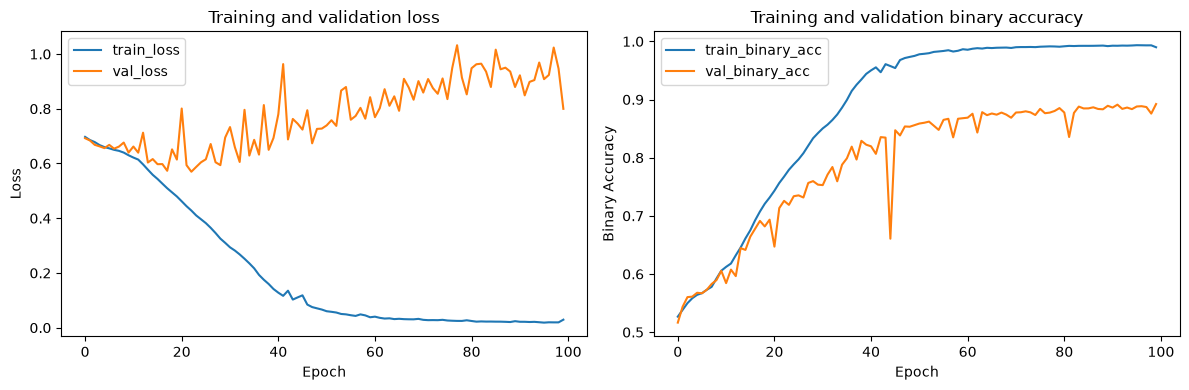

In [14]:
# Plot training history if available.

if "history" in globals():
    plt.figure(figsize=(12, 4))

    # Loss curve.
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()

    # Binary accuracy curve.
    plt.subplot(1, 2, 2)
    plt.plot(history.history["binary_accuracy"], label="train_binary_acc")
    plt.plot(history.history["val_binary_accuracy"], label="val_binary_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Accuracy")
    plt.title("Training and validation binary accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No training history found.")



# 6. Evaluate the model

The test set is used only after training.

Important:

- `binary_accuracy` measures label-wise correctness.
- `precision` measures whether predicted labels are correct.
- `recall` measures whether true labels are found.
- `exact_match_accuracy` checks whether the whole label set is correct for each image.

For this task, precision, recall, and exact-match accuracy are usually more informative than binary accuracy.


In [15]:
# Evaluate the model on the test set.
results = model.evaluate(x_test, y_test, verbose=1)

# print("\nTest results:")
# for name, value in zip(model.metrics_names, results):
#     print(f"{name}: {value:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - binary_accuracy: 0.9045 - exact_match_accuracy: 0.3985 - loss: 0.7021 - precision: 0.9227 - recall: 0.8911



# 7. Visualize predictions

The model outputs probabilities.

Example:

```text
digit 0: 0.02
digit 1: 0.91
digit 2: 0.04
...
```

If a probability is greater than or equal to the threshold, that digit is predicted as present.


In [16]:
# Prediction helper functions
# Student donnt allow to change the threshold value
PREDICTION_THRESHOLD=0.5
def probs_to_digits(probs, threshold=PREDICTION_THRESHOLD):
    """Convert prediction probabilities into a list of predicted digits."""
    return np.where(probs >= threshold)[0].tolist()


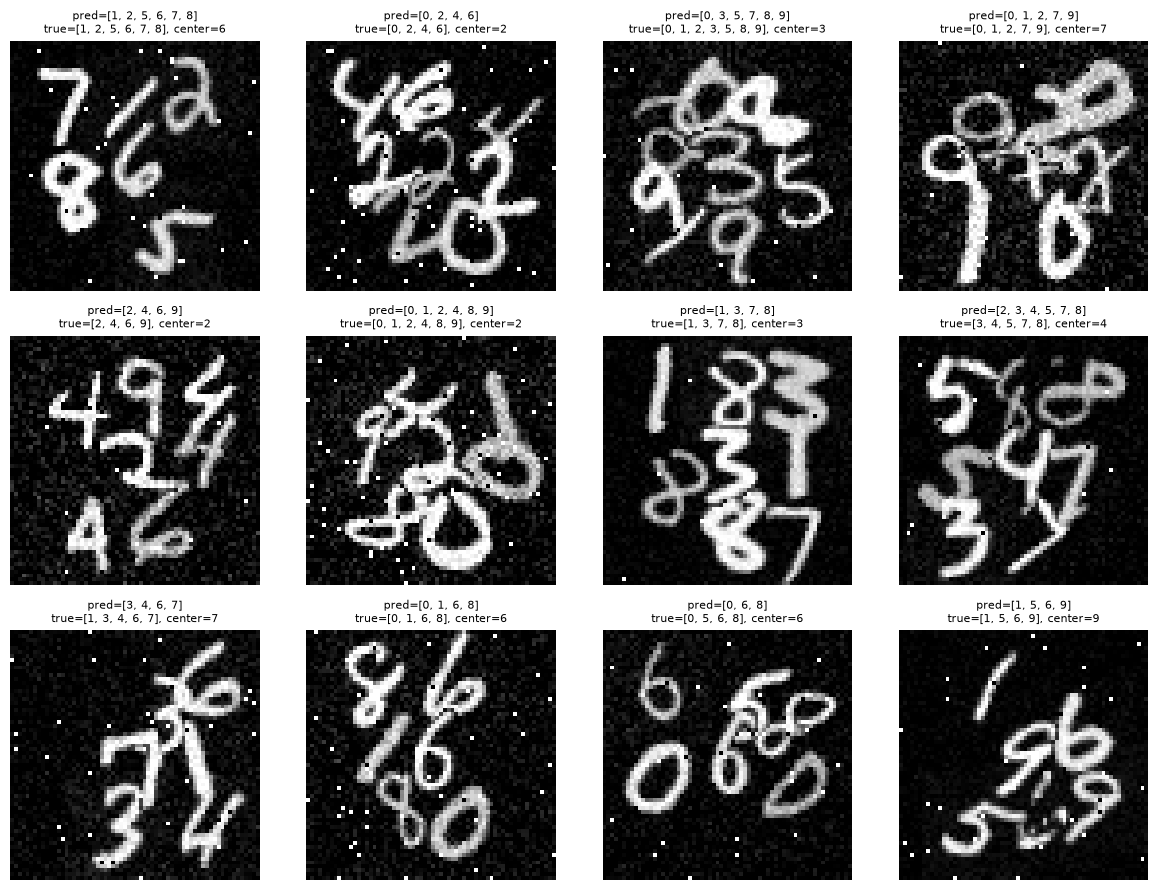

In [17]:

# Visualize several test predictions.

if "model" in globals() and "x_test" in globals():
    indices = np.random.choice(len(x_test), size=12, replace=False)
    probs = model.predict(x_test[indices], verbose=0)

    plt.figure(figsize=(12, 9))

    for i, idx in enumerate(indices):
        true_digits = multihot_to_digits(y_test[idx])
        pred_digits = probs_to_digits(probs[i], threshold=PREDICTION_THRESHOLD)
        center_label = meta_test["center_labels"][idx]

        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"pred={pred_digits}\n"
            f"true={true_digits}, center={center_label}",
            fontsize=8,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Model or test data not available.")


In [ ]:

# Inspect one test prediction in detail.
idx = 0
prob = model.predict(x_test[idx:idx + 1], verbose=0)[0]

print("True digits:", multihot_to_digits(y_test[idx]))
print("Predicted digits:", probs_to_digits(prob))
print("Center label:", meta_test["center_labels"][idx])
print()

print("Prediction probabilities:")
for digit, p in enumerate(prob):
    print(f"digit {digit}: {p:.4f}")


True digits: [2, 3, 5, 7, 9]
Predicted digits: [2, 3, 5, 7, 9]
Center label: 7

Prediction probabilities:
digit 0: 0.0000
digit 1: 0.0000
digit 2: 1.0000
digit 3: 1.0000
digit 4: 0.0000
digit 5: 1.0000
digit 6: 0.0005
digit 7: 1.0000
digit 8: 0.0000
digit 9: 1.0000


: 

In [ ]:
# Exit kernel
import os
os.kill(os.getpid(), 9)